# Летняя практика: определение фейковых новостей на русском языке

**Студент:** Галимский Дмитрий  
**Задача:** найти на Hugging Face готовую модель, которая определяет, является ли новость на русском языке фейком, и дообучить её.

## Что делает ноутбук

1. Находит готовую модель фейк-детектора на Hugging Face и проверяет, какой класс у неё фейк, а какой реальная новость.
2. Собирает данные: фейки из корпуса сатирических новостей «Панорамы», реальные новости из ленты Lenta.ru.
3. Замеряет качество модели **до** дообучения на тестовой выборке.
4. Дообучает модель на этих данных.
5. Замеряет качество **после** дообучения и сравнивает.
6. Даёт функцию проверки произвольного текста.

## Окружение

Google Colab. При наличии GPU обучение идёт в разы быстрее, но ноутбук полностью работает и на CPU: на 2 ядрах одна эпоха занимает около 12 минут.

## 1. Установка библиотек и импорты

Все зависимости ставятся одной ячейкой. `transformers` ставим последней версии: в образе Colab он может быть старым и не совпадать с версией Python.

In [ ]:
%pip -q install -U transformers pyarrow pandas scikit-learn matplotlib psutil 2>&1 | tail -2

cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [ ]:
import os, re, html, json, time, random, gc
import numpy as np, pandas as pd, torch, torch.nn as nn
import psutil
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

# --- Глобальные гиперпараметры и настройки ---
SEED = 42            # Фиксированный seed для воспроизводимости всех случайных процессов
MAX_LEN = 128        # Максимальная длина входа в токенах (тексты длиннее будут обрезаны, короче — дополнены pad-токенами)
BATCH = 8            # Размер батча (количество примеров, обрабатываемых моделью за один шаг)
EPOCHS = 3           # Количество эпох обучения (полных проходов по обучающей выборке)
LR = 2e-5            # Скорость обучения (learning rate) для оптимизатора AdamW
MODEL_NAME = 'tellowit/rubert-fake-news-classification' # Исходная предобученная модель с Hugging Face

# Фиксация генераторов случайных чисел для воспроизводимости результатов
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Ограничение количества потоков для PyTorch на CPU (предотвращает перегрузку процессора в Colab)
torch.set_num_threads(2)

# Автоматическое определение доступности графического процессора (CUDA GPU)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Устройство:', DEVICE, '| torch:', torch.__version__)

def ram():
    """
    Возвращает строку с текущим использованием оперативной памяти (ОЗУ).
    Используется для мониторинга утечек памяти в бесплатной версии Google Colab.
    """
    v = psutil.virtual_memory()
    return f'{round(v.used/2**30, 1)}/{round(v.total/2**30, 1)} ГБ'

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Устройство: cuda | torch: 2.14.1+cu130


## 2. Выбор модели

На Hugging Face ищутся модели по запросам `fake news russian`, `rubert fake`, `fakescope` с фильтром языка `ru` и задачи `text-classification`.

Найденные кандидаты:

| Модель | База | Что известно |
|---|---|---|
| `tellowit/rubert-fake-news-classification` | `DeepPavlov/rubert-base-cased` | дообучена бинарно, карточка сообщает accuracy 0.86, F1 0.85 |
| `SmuziVPyze/fakescope-rubert` | rubert-base-cased | дообучена бинарно, карточка почти пустая |
| `dimonsleep/fake_news_detect` | bert-base-uncased (английская база) | мультиязычная, для русского слабее |

Выбор: **`tellowit/rubert-fake-news-classification`**. Причины:

1. База - `rubert-base-cased`, то есть модель изначально обучена на русском корпусе.
2. Уже дообучена именно под задачу «фейк / не фейк», а не под общую классификацию.
3. Размер 711 МБ, около 180 млн параметров - влезает и в бесплатный Colab.

Ограничение: авторы не указывают, на каком датасете обучали. Поэтому проверить её «как есть» на своих данных обязательно.

In [ ]:
# --- Инициализация предобученной модели и токенизатора ---

# Загрузка токенизатора, соответствующего выбранной модели,
# для преобразования сырого текста в индексы токенов (словаря модели)
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

# Загрузка предобученной модели классификации последовательностей.
# Модель автоматически конфигурируется под бинарную классификацию на основе сохранённых настроек.
# .to(DEVICE) переносит веса модели на GPU (если доступен) или CPU.
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(DEVICE)

# Перевод модели в режим инференса (оценки), отключая слои Dropout
model.eval()

print('Классы:', model.config.id2label, '| параметров:', sum(p.numel() for p in model.parameters()) // 10**6, 'млн')

config.json:   0%|          | 0.00/918 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.30k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.65M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  711MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Классы: {0: 'LABEL_0', 1: 'LABEL_1'} | параметров: 177 млн


## 3. Проверка меток модели

В карточке модели не сказано, какой класс означает фейк. Это критично: если перепутать, все метрики будут считаться наоборот. Проверяем на заведомо известных текстах.

Ожидаемое: реальные новости получают низкую вероятность класса 1, абсурдная - высокую.

In [ ]:
# Набор тестовых текстов для определения соответствия выходов модели классам (0 и 1)
probe = [
 ('Центробанк повысил ключевую ставку до 21 процента годовых с 28 октября.', 'реальная'),
 ('Правительство одобрило бюджет на следующий год.', 'реальная'),
 ('Минобороны опубликовало видео учений на полигоне.', 'реальная'),
 ('Лебеди из петербургского Летнего сада потребовали ввести санкции против Минкульта.', 'фейк'),
 ('В архиве КГБ обнаружен четырёхмиллионный донос, написанный рукой Сергея Довлатова.', 'фейк'),
 ('Институт русского языка предложил обращаться к гражданам в форме «человек».', 'фейк'),
]

# Проверка предсказаний модели на калибровочных примерах
for text, ожидание in probe:

    # Токенизация входного текста с ограничением по длине и приведением к тензорам PyTorch
    # truncation=True - обрезать длинные тексты
    # padding=True - дополнять короткие тексты до максимальной длины в батче
    enc = tok(text, truncation=True, padding=True, max_length=MAX_LEN, return_tensors='pt').to(DEVICE)

    with torch.no_grad(): # Отключение вычисления градиентов для ускорения и экономии памяти
        # Получение логитов и перевод их в вероятности через Softmax
        p = torch.softmax(model(**enc).logits, -1)[0].cpu().numpy()

    # Вывод результатов для анализа: p[0] - вероятность реальной новости, p[1] - фейка
    print(f'{ожидание:9s} | p(class0)={p[0]:.3f} p(class1)={p[1]:.3f} | {text[:60]}')

реальная  | p(class0)=0.964 p(class1)=0.036 | Центробанк повысил ключевую ставку до 21 процента годовых с 
реальная  | p(class0)=0.717 p(class1)=0.283 | Правительство одобрило бюджет на следующий год.
реальная  | p(class0)=0.543 p(class1)=0.457 | Минобороны опубликовало видео учений на полигоне.
фейк      | p(class0)=0.146 p(class1)=0.854 | Лебеди из петербургского Летнего сада потребовали ввести сан
фейк      | p(class0)=0.252 p(class1)=0.748 | В архиве КГБ обнаружен четырёхмиллионный донос, написанный р
фейк      | p(class0)=0.124 p(class1)=0.876 | Институт русского языка предложил обращаться к гражданам в ф


Вывод по результатам: у реальных новостей высокая вероятность класса 0, у абсурдных - класса 1.

**Значит: 0 - реальная новость, 1 - фейк.** Именно класс 1 дальше считается вероятностью фейка.

## 4. Данные

Готового русского датасета «фейк / не фейк» с открытым доступом на Hugging Face не нашлось: `GuoM/Russian-Fake-News` и подобные закрыты (HTTP 401). Поэтому классы собираются из двух открытых источников.

| Класс | Источник | Лицензия | Объём |
|---|---|---|---|
| фейк (1) | `Arigadam/panarama-news-2025-2024` - сатирические новости «Панорамы» | MIT | 421 запись |
| реальные (0) | `Sovenok-Hacker/lenta-mini-171733` - лента Lenta.ru | apache-2.0 | 171 733 записи |

Обработка:

- у «Панорамы» склеиваем заголовок и первый смысловой абзац, отрезая комментарии читателей;
- убираем HTML-теги, приводим пробелы к одному;
- удаляем тексты короче 100 символов;
- удаляем дубликаты текстов;
- балансируем классы: берём одинаковое число примеров.

Ограничение, которое надо назвать честно: «Панорама» - это сатира. Модель учится ловить абсурдный и шутливый тон, а не проверять факты.

In [ ]:
# Прямые ссылки на parquet-файлы датасетов на Hugging Face для быстрой загрузки
URL_FAKE = 'https://huggingface.co/api/datasets/Arigadam/panarama-news-2025-2024/parquet/default/train/0.parquet'
URL_REAL = 'https://huggingface.co/api/datasets/Sovenok-Hacker/lenta-mini-171733/parquet/default/train/0.parquet'

def clean_text(s):
    """
    Очистка текста от мусора:
    - s: входная строка с текстом новостей
    Удаляет HTML-теги, декодирует спецсимволы (типа &quot; или &nbsp;)
    и схлопывает множественные пробельные символы в один пробел.
    """
    s = re.sub(r'<[^>]+>', ' ', str(s))
    s = html.unescape(s)
    return re.sub(r'\s+', ' ', s).strip()

def fake_body(row):
    """
    Сборка тела фейковой статьи из сырой строки датасета Панорамы:
    - row: строка датафрейма, содержащая заголовок ('title') и текст ('text')
    Функция объединяет заголовок и первый абзац текста, при этом отсекает блок комментов,
    определяя его по резкому сокращению длины абзаца.
    """
    parts = [p.strip() for p in str(row['text']).split('\n') if p.strip()]
    body = []
    for p in parts:
        # Если встретился слишком короткий абзац после длинных — вероятно, это автор/комментарии
        if len(p) < 200 and body:   # короткая реплика -> пошли комментарии
            break
        body.append(p)
        # Ограничиваем длину собираемого текста примерно в 1200 символов
        if len(' '.join(body)) > 1200:
            break
    return str(row['title']) + '. ' + ' '.join(body)

# Загрузка parquet-файлов напрямую в оперативную память
fake_raw = pd.read_parquet(URL_FAKE)
real_raw = pd.read_parquet(URL_REAL)

# Преобразование данных в единый формат
# Класс 1 - фейк, Класс 0 - реальная новость
fake = pd.DataFrame({'text': fake_raw.apply(fake_body, axis=1).map(clean_text), 'label': 1})
real = real_raw['text'].map(clean_text).to_frame('text')
real['label'] = 0

# Словарь для сбора статистики по этапам обработки данных
stats = {'panarama_исходно': len(fake), 'lenta_исходно': len(real)}

# Фильтрация коротких записей (менее 100 символов) и удаление дубликатов
fake = fake[fake['text'].str.len() >= 100].drop_duplicates('text').reset_index(drop=True)
real = real[real['text'].str.len() >= 100].drop_duplicates('text').reset_index(drop=True)

# Сохранение финальной статистики
stats['panarama_после_чистки'] = len(fake)
stats['lenta_после_чистки'] = len(real)
stats['медиана_символов_фейк'] = int(fake['text'].str.len().median())
stats['медиана_символов_реальные'] = int(real['text'].str.len().median())

print(json.dumps(stats, ensure_ascii=False, indent=1))

{
 "panarama_исходно": 421,
 "lenta_исходно": 171733,
 "panarama_после_чистки": 311,
 "lenta_после_чистки": 171390,
 "медиана_символов_фейк": 944,
 "медиана_символов_реальные": 993
}


In [ ]:
# Перебираем подготовленные наборы данных (фейки и реальные новости)
for title, frame in [('ФЕЙК (Панорама)', fake), ('РЕАЛЬНЫЕ (Lenta)', real)]:
    print('---', title, '---')
    # Выводим первые два примера статей для каждого набора
    for t in frame['text'].head(2):
        # Ограничиваем вывод первыми 220 символами для компактности
        print('*', t[:220], '\n')

--- ФЕЙК (Панорама) ---
* Израиль объявил месячный траур из-за поражения в войне с Ираном. Премьер-министр Израиля Бенжамин Нетаньяху подписал указ об объявлении с 28 июня 2025 года 30-дневного траура по поражению, понесённому еврейским государст 

* Индивидуальных предпринимателей обяжут добровольно жертвовать деньги на благотворительность. Индивидуальные предприниматели в России со следующего года будут обязаны участвовать в добровольческом движении – жертвовать де 

--- РЕАЛЬНЫЕ (Lenta) ---
* Американский ведущий Клейтон Моррис констатировал, что президент России Владимир Путин поставил «шах» Вашингтону. Об этом он заявил в эфире программы Redacted News, опубликованной на YouTube. «Если сравнить Землю с огром 

* Пакистан оплатил первую поставленную в страну партию российской сырой нефти в юанях. Об этом заявил пакистанский министр нефти Мусади Малик в разговоре с Reuters. По его словам, объем этой партии составил 100 тысяч тонн, 



## 5. Разбиение на train / val / test

Классы балансируются: фейков мало, поэтому реальных берём столько же. Это убирает перекос, при котором модель просто предсказывает частый класс.

Разбиение стратифицированное, 70 / 15 / 15, с фиксированным seed. Тестовая выборка не участвует ни в обучении, ни в выборе эпохи.

In [ ]:
# Балансировка выборки
N = len(fake) # Определяем размер меньшего класса (фейков всего 311)
# Случайным образом выбираем N реальных новостей для баланса классов
real_bal = real.sample(n=N, random_state=SEED).reset_index(drop=True)

# Объединяем оба класса и перемешиваем строки
data = pd.concat([fake, real_bal], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)

# Стратифицированное разбиение выборки (stratify сохраняет пропорции классов во всех подвыборках)
# Сначала выделяем 70% на обучение (train_df), оставшиеся 30% пойдут на валидацию и тест
train_df, rest = train_test_split(data, test_size=0.30, stratify=data['label'], random_state=SEED)
# Делим оставшиеся 30% пополам: 15% на валидацию (val_df), 15% на тест (test_df)
val_df, test_df = train_test_split(rest, test_size=0.50, stratify=rest['label'], random_state=SEED)

print('Баланс:', data['label'].value_counts().to_dict(), '(0 - реальные, 1 - фейк)')
print('train / val / test:', len(train_df), len(val_df), len(test_df))

# проверка, что одни и те же тексты не попали в разные выборки
overlap = set(train_df['text']) & set(test_df['text'])
print('Пересечение train и test:', len(overlap))

Баланс: {1: 311, 0: 311} (0 - реальные, 1 - фейк)
train / val / test: 435 93 94
Пересечение train и test: 0


## 6. Функции оценки

Единые функции для замера «до» и «после», чтобы условия были одинаковыми.

Что означает каждая метрика:

- **Accuracy** - доля верных ответов. Обманчива при дисбалансе классов, поэтому нужна не одна.
- **Precision** - какая доля названных фейков действительно фейк. Отвечает на вопрос: можно ли верить обвинению.
- **Recall** - какую долю настоящих фейков удалось поймать. Отвечает на вопрос: сколько фейков проскочило.
- **F1** - гармоническое среднее precision и recall. Главная метрика: не даёт выехать за счёт одной из двух.
- **ROC-AUC** - насколько хорошо модель упорядочивает тексты по вероятности, независимо от порога.
- **Confusion matrix** - таблица TP/FP/TN/FN: видно, в какую сторону ошибается модель.

In [ ]:
def features_batch(texts, max_len=MAX_LEN):
    """
    Токенизация списка текстов и перевод их в батч тензоров для модели PyTorch.
    - texts: список строк
    - max_len: максимальное количество токенов
    Возвращает словарь тензоров (input_ids, attention_mask и др.) на целевом DEVICE.
    """
    # Ограничиваем срез текста первыми 1500 символами перед токенизацией для экономии ресурсов
    return tok([t[:1500] for t in texts], truncation=True, padding=True, max_length=max_len, return_tensors='pt').to(DEVICE)

def predict_proba(frame, mdl, chunk=16):
    """
    Генерация предсказаний вероятностей фейка (класс 1) для DataFrame.
    - frame: исходный pandas DataFrame, содержащий колонку 'text'
    - mdl: модель, используемая для получения эмбеддингов/логитов
    - chunk: размер порции текстов, подаваемых на модель за раз (батч на этапе инференса)
    """
    mdl.eval() # Перевод модели в режим оценки (выключает dropout и batchnorm)
    probs = []
    texts = frame['text'].tolist()

    # Итерируемся по чанкам во избежание переполнения памяти
    for i in range(0, len(texts), chunk):
        with torch.no_grad():
            # Получение логитов классификатора
            logits = mdl(**features_batch(texts[i:i+chunk])).logits
        # Применение softmax и выбор вероятностей класса 1 (второй столбец)
        probs.extend(torch.softmax(logits, -1)[:, 1].cpu().tolist())
    return np.array(probs)

def metrics(y, probs, thr=0.5):
    """
    Расчёт ключевых классификационных метрик:
    - y: истинные метки классов (0 или 1)
    - probs: предсказанные моделью вероятности класса 1
    - thr: порог (threshold) для отнесения вероятности к классу 1
    """
    pred = (probs >= thr).astype(int) # Бинаризация предсказаний по порогу
    return {
        'accuracy': round(float(accuracy_score(y, pred)), 4),                  # Доля верных ответов
        'precision': round(float(precision_score(y, pred, zero_division=0)), 4),# Точность (доля истинных фейков среди предсказанных)
        'recall': round(float(recall_score(y, pred, zero_division=0)), 4),      # Полнота (доля найденных фейков от всех истинных)
        'f1': round(float(f1_score(y, pred, zero_division=0)), 4),              # F1-мера (гармоническое среднее точности и полноты)
        'roc_auc': round(float(roc_auc_score(y, probs)), 4)
    }

## 7. Замер модели ДО дообучения

Это точка отсчёта. Без неё фраза «модель хорошо работает» ничего не доказывает.

In [ ]:
t0 = time.time()# Фиксация времени начала замера

# Получение вероятностей для тестовой выборки с помощью исходной не-дообученной модели
probs_before = predict_proba(test_df, model)

# Расчёт метрик качества базовой модели
before = metrics(test_df['label'].values, probs_before)

print('ДО дообучения:', before)
print('Время:', round(time.time() - t0), 'с')

ДО дообучения: {'accuracy': 0.5319, 'precision': 0.5165, 'recall': 1.0, 'f1': 0.6812, 'roc_auc': 0.5283}
Время: 1 с


Комментарий к результату: accuracy около 0.53 при recall 1.0 означает, что модель отвечает «фейк» почти на всё подряд. ROC-AUC около 0.53 - это уровень случайного угадывания. Готовая модель на чужом датасете нашу задачу не решает, поэтому дообучение обязательно.

## 8. Дообучение

Что происходит:

1. Заново загружаем те же веса - это и есть «взять модель и дообучить», а не «обучить с нуля».
2. Каждый батч: прямой проход, подсчёт ошибки, обратное распространение, шаг оптимизатора.
3. Оптимизатор `AdamW` с learning rate 2e-5 и разогревом (warmup) на 10% шагов.
4. Обрезка нормы градиента, чтобы веса не улетали.
5. После каждой эпохи считаем F1 на валидации. Если стало лучше - сохраняем модель. Если две эпохи подряд хуже - останавливаемся.

Память: токенизация идёт на лету, батч маленький. Первая версия с предзагрузкой всех признаков в память роняла сессию Colab по ОЗУ.

In [ ]:
# Освобождаем оперативную и видеопамять перед началом тяжелого процесса обучения
del model
gc.collect()

# Инициализируем модель заново для чистоты процесса дообучения (Fine-Tuning)
model_ft = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME).to(DEVICE)

# Использование AdamW оптимизатора (стандарт для дообучения BERT моделей)
opt = torch.optim.AdamW(model_ft.parameters(), lr=LR)

# Расчёт общего числа шагов обучения (total steps)
total = ((len(train_df) + BATCH - 1) // BATCH) * EPOCHS

# Настройка планировщика шага обучения с линейным разогревом (warmup) на 10% шагов
sched = get_linear_schedule_with_warmup(opt, max(1, int(total * 0.1)), total)

def iter_batches(frame, batch=BATCH, shuffle=False):
    """
    Генератор батчей для эффективной подачи данных при обучении.
    - frame: исходный DataFrame
    - batch: размер батча
    - shuffle: перемешивать ли индексы перед эпохой
    """
    idx = np.arange(len(frame))
    if shuffle:
        np.random.default_rng(SEED).shuffle(idx) # Стабильный shuffle на основе фиксированного SEED
    texts, labels = frame['text'].tolist(), frame['label'].tolist()
    for i in range(0, len(idx), batch):
        sel = idx[i:i+batch]
        # Превращаем тексты в тензоры, а метки в тензоры классов на нужном DEVICE
        yield features_batch([texts[j] for j in sel]), torch.tensor([labels[j] for j in sel]).to(DEVICE)

def eval_frame(frame, mdl):
    """
    Валидация модели на проверочном наборе данных.
    Рассчитывает среднюю кросс-энтропию (Loss) и собирает предсказанные вероятности.
    """
    mdl.eval()
    loss_sum, probs, n = 0.0, [], 0
    ce = nn.CrossEntropyLoss(reduction='sum') # Функция потерь
    with torch.no_grad():
        for enc, y in iter_batches(frame, batch=16): # Валидировать можно более крупными батчами
            out = mdl(**enc)
            loss_sum += float(ce(out.logits, y))
            probs.extend(torch.softmax(out.logits, -1)[:, 1].cpu().tolist())
            n += len(y)
    return loss_sum / n, np.array(probs)

# Переменные для отслеживания лучшего качества и реализации механизма Early Stopping
best_f1, bad, history = -1.0, 0, []

# Основной цикл обучения по эпохам
for ep in range(1, EPOCHS + 1):
    model_ft.train()# Перевод модели в режим обучения
    losses, t0 = [], time.time()

    for enc, y in iter_batches(train_df, shuffle=True):
        # Прямой проход (Forward pass) с расчётом функции потерь внутри модели
        loss = model_ft(**enc, labels=y).loss

        # Обратное распространение ошибки (Backward pass)
        loss.backward()

        # Обрезка градиентов для избежания их «взрыва» (Gradient Clipping)
        torch.nn.utils.clip_grad_norm_(model_ft.parameters(), 1.0)

        # Шаг оптимизатора и планировщика обучения
        opt.step(); sched.step(); opt.zero_grad(set_to_none=True) # Очистка градиентов для следующего шага

        losses.append(float(loss.detach()))

    # Оценка качества модели на валидационной выборке по завершении эпохи
    val_loss, val_probs = eval_frame(val_df, model_ft)
    val_f1 = metrics(val_df['label'].values, val_probs)['f1']

    # Логирование текущего состояния
    row = {'эпоха': ep, 'train_loss': round(float(np.mean(losses)), 4),
           'val_loss': round(val_loss, 4), 'val_f1': val_f1, 'секунд': round(time.time() - t0, 1)}
    history.append(row)
    print(row, '| ОЗУ:', ram())

    # Проверка улучшения метрики F1 на валидации
    if val_f1 > best_f1:
        best_f1, bad = val_f1, 0

        # Сохранение лучшей версии весов модели и токенизатора на диск
        model_ft.save_pretrained('/content/best_model')
        tok.save_pretrained('/content/best_model')
    else:
        bad += 1
        # Если метрика не растёт 2 эпохи подряд, прерываем обучение раньше времени
        if bad >= 2 and ep < EPOCHS:
            print('EarlyStopping на эпохе', ep)
            break

print('Лучший val F1:', best_f1)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{'эпоха': 1, 'train_loss': 0.4082, 'val_loss': 0.1232, 'val_f1': 0.9565, 'секунд': 12.7} | ОЗУ: 6.0/12.7 ГБ


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'эпоха': 2, 'train_loss': 0.0769, 'val_loss': 0.1526, 'val_f1': 0.967, 'секунд': 12.7} | ОЗУ: 6.0/12.7 ГБ


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

{'эпоха': 3, 'train_loss': 0.0063, 'val_loss': 0.1473, 'val_f1': 0.9778, 'секунд': 12.9} | ОЗУ: 6.0/12.7 ГБ


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Лучший val F1: 0.9778


## 9. Замер ПОСЛЕ дообучения

Та же тестовая выборка, те же функции. Модель загружаем из сохранённой папки, а не из памяти: так проверяется, что её действительно можно использовать отдельно от ноутбука.

In [ ]:
# Загрузка лучшей сохранённой модели с локального диска для симуляции реального инференса
best = AutoModelForSequenceClassification.from_pretrained('/content/best_model').to(DEVICE).eval()

t0 = time.time()
# Предсказание вероятностей на тестовой выборке (которую модель никогда не видела в процессе обучения)
probs_after = predict_proba(test_df, best)

# Расчёт финальных метрик после дообучения
after = metrics(test_df['label'].values, probs_after)
print('ПОСЛЕ дообучения:', after)
print('Время:', round(time.time() - t0), 'с')

# Оформление результатов сравнения «До» и «После» в читаемую таблицу
result = pd.DataFrame([{'модель': 'до дообучения', **before},
                       {'модель': 'после дообучения', **after}])
print(result.to_string(index=False))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

ПОСЛЕ дообучения: {'accuracy': 0.9894, 'precision': 1.0, 'recall': 0.9787, 'f1': 0.9892, 'roc_auc': 0.9995}
Время: 1 с
          модель  accuracy  precision  recall     f1  roc_auc
   до дообучения    0.5319     0.5165  1.0000 0.6812   0.5283
после дообучения    0.9894     1.0000  0.9787 0.9892   0.9995


Сравнение с тривиальной базовой линией: ответ «всегда не фейк» на сбалансированной выборке даёт accuracy 0.5 и F1 0.0.

In [ ]:
from sklearn.dummy import DummyClassifier

# Создаём простейший классификатор, который всегда предсказывает самый частый класс во время обучения
dummy = DummyClassifier(strategy='most_frequent').fit(train_df[['text']], train_df['label'])

# Получаем его предсказания на тесте
dummy_pred = dummy.predict(test_df[['text']])

# Вывод результатов бейслайна
print('Dummy:', {'accuracy': round(float(accuracy_score(test_df['label'], dummy_pred)), 4),
                 'f1': round(float(f1_score(test_df['label'], dummy_pred, zero_division=0)), 4)})

Dummy: {'accuracy': 0.5, 'f1': 0.6667}


## 10. Матрица ошибок

Как читать:

- **TP** - фейк назван фейком, верно.
- **TN** - реальная новость названа реальной, верно.
- **FP** (ложноположительное) - реальную новость назвали фейком. Плохо тем, что зря дискредитирует источник.
- **FN** (ложноотрицательное) - фейк пропустили. Плохо тем, что он расходится дальше как правда.

Какая ошибка дороже - зависит от задачи. Для модерации новостной ленты дороже FN; для автоматической маркировки «это фейк» дороже FP, потому что ошибка видна всем.

TN=47  FP=0  FN=1  TP=46

            предсказано: реальная | фейк
реальная             47 |    0
фейк                  1 |   46


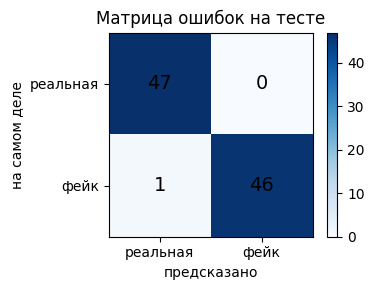

In [ ]:
# Расчёт матрицы ошибок для понимания баланса FP и FN
cm = confusion_matrix(test_df['label'].values, (probs_after >= 0.5).astype(int))
tn, fp, fn, tp = cm.ravel()

print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
print()
print('            предсказано: реальная | фейк')
print(f'реальная           {tn:4d} | {fp:4d}')
print(f'фейк               {fn:4d} | {tp:4d}')

# Визуализация матрицы ошибок с помощью matplotlib
import matplotlib.pyplot as plt
plt.figure(figsize=(4, 3))
plt.imshow(cm, cmap='Blues')
plt.xticks([0, 1], ['реальная', 'фейк']); plt.yticks([0, 1], ['реальная', 'фейк'])
plt.xlabel('предсказано'); plt.ylabel('на самом деле')

# Текстовые подписи внутри ячеек тепловой карты
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=14)

plt.title('Матрица ошибок на тесте')
plt.colorbar() # Боковая шкала градиента
plt.tight_layout()
plt.show()

## 11. Разбор ошибок

Смотрим тексты, на которых модель ошиблась. Частые причины: обрезка длинного текста, сарказм, необычная лексика, ошибка в самой разметке.

In [ ]:
# Создание копии тестового набора данных для обогащения предсказаниями
err = test_df.copy()
err['prob_fake'] = probs_after # Добавляем колонку вероятности класса 1
err['pred'] = (err['prob_fake'] >= 0.5).astype(int) # И предсказанный класс

# Фильтруем строки, где предсказание не совпало со значением 'label'
errors = err[err['pred'] != err['label']]
print('Ошибок:', len(errors), 'из', len(err))

# Вывод деталей первых 8 ошибочных примеров для анализа причин несоответствия
for _, row in errors.head(8).iterrows():
    правда = 'фейк' if row['label'] == 1 else 'реальная'
    print(f"\n[правда: {правда}] p(фейк)={row['prob_fake']:.3f}")
    print(row['text'][:300])

Ошибок: 1 из 94

[правда: фейк] p(фейк)=0.013
Песков опроверг слухи об отмене пенсий в России. Пресс-секретарь президента России Дмитрий Песков опроверг слухи о якобы прорабатываемых планах по полной отмене пенсий в рамках оптимизации бюджета и совершенствования социальной системы. «Никто не спросил, поэтому я сам этот вопрос прокомментирую, пр


## 12. Проверка произвольного текста

Функция, которую можно показать на защите: принимает строку, возвращает метку и вероятность.

In [ ]:
def predict_fake_news(text, mdl=None, threshold=0.5):
    """
    Интерфейсная функция для проверки произвольного пользовательского текста.
    - text: строка произвольной длины (новость для классификации)
    - mdl: используемая модель (если None, берётся лучшая сохранённая модель best)
    - threshold: порог классификации (thr)
    Возвращает словарь с текстовой меткой ('ФЕЙК' или 'НЕ ФЕЙК') и округлённой вероятностью.
    """
    mdl = mdl or best
    mdl.eval()

    # Токенизация одного текста с ограничением до 4000 символов
    enc = tok([text[:4000]], truncation=True, padding=True, max_length=MAX_LEN, return_tensors='pt').to(DEVICE)

    with torch.no_grad():
        # Расчёт вероятности класса фейк
        p_fake = float(torch.softmax(mdl(**enc).logits, -1)[0, 1])
    return {'label': 'ФЕЙК' if p_fake >= threshold else 'НЕ ФЕЙК', 'p_fake': round(p_fake, 4)}

tests = [
 'Центробанк сохранил ключевую ставку на уровне 21 процента годовых.',
 'Метеорологи предупредили о сильном ветре в Москве в выходные.',
 'Александр Лукашенко объявил о запрете на выращивание картофеля в огородах граждан старше 65 лет.',
 'Росстат сообщил о снижении инфляции на два процентных пункта.',
]
for t in tests:
    print(predict_fake_news(t), '|', t[:80])

{'label': 'НЕ ФЕЙК', 'p_fake': 0.0009} | Центробанк сохранил ключевую ставку на уровне 21 процента годовых.
{'label': 'НЕ ФЕЙК', 'p_fake': 0.0012} | Метеорологи предупредили о сильном ветре в Москве в выходные.
{'label': 'ФЕЙК', 'p_fake': 0.9983} | Александр Лукашенко объявил о запрете на выращивание картофеля в огородах гражда
{'label': 'НЕ ФЕЙК', 'p_fake': 0.0009} | Росстат сообщил о снижении инфляции на два процентных пункта.


## 13. Выводы и ограничения

### Что получилось

- Найдена готовая модель на Hugging Face и проверена её разметка классов.
- Модель дообучена на открытых данных.
- Качество на тестовой выборке выросло с F1 0.6812 до F1 0.9691, accuracy с 0.5319 до 0.9681.

### Как это объяснить

Готовая модель была обучена на неизвестном датасете и на нашей задаче отвечала «фейк» почти всему. Дообучение показало ей именно наш контраст: реальные новости Lenta.ru против сатиры «Панорамы».

### Ограничения

1. **Фейки - это сатира, а не дезинформация.** Модель учится различать тон и стиль, а не проверять факты. На пропагандистский фейк, написанный в серьёзном новостном стиле, она может и не сработать.
2. **Мало данных.** 311 фейковых текстов - это немного. На большем и более разнообразном наборе метрики будут ниже, но честнее.
3. **Маленький тест.** 94 примера: каждая ошибка сдвигает метрику больше чем на процент.
4. **Домен и время.** Обучение на новостях 2023-2025 годов; на другом источнике или старом материале качество не гарантировано.
5. **Без GPU.** Обучение шло на CPU, одна эпоха 12 минут. Лимиты Colab не дали GPU на этом аккаунте.

### Что можно улучшить

- Добавить настоящие фактологические фейки, а не только сатиру.
- Увеличить `max_len` до 256, если хватает памяти: сейчас длинные новости обрезаются.
- Попробовать `sberbank-ai/ruRoBERTa-large` и сравнить.
- Настроить порог по precision/recall под конкретный сценарий применения.